# Level 3 — Task 3: Price Range vs Online Delivery and Table Booking

### Do Higher-Priced Restaurants Offer More Services?

This dataset contains 9,551 restaurant listings scraped from a Zomato-style
platform, covering cuisine type, cost, ratings, and location across multiple
cities and countries.

**Business question:** Is a restaurant's price range linked to whether it offers
online delivery and table booking? Are premium restaurants more likely to offer
these services?

**Objectives:**
1. Analyze whether there is a relationship between the price range and the
   availability of online delivery and table booking.
2. Determine if higher-priced restaurants are more likely to offer these services.

## 1. Dataset Overview

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

### Note: filename has a trailing space as saved in the data folder

In [2]:
df = pd.read_csv("../../data/Dataset .csv")
df.head()

,Restaurant ID,Restaurant Name,Country Code,City,Address,Locality,Locality Verbose,Longitude,Latitude,Cuisines,...,Currency,Has Table booking,Has Online delivery,Is delivering now,Switch to order menu,Price range,Aggregate rating,Rating color,Rating text,Votes
0,6317637,Le Petit Souffle,162,Makati City,"Third Floor, Century City Mall, Kalayaan Avenu...","Century City Mall, Poblacion, Makati City","Century City Mall, Poblacion, Makati City, Mak...",121.027535,14.565443,"French, Japanese, Desserts",...,Botswana Pula(P),Yes,No,No,No,3,4.8,Dark Green,Excellent,314
1,6304287,Izakaya Kikufuji,162,Makati City,"Little Tokyo, 2277 Chino Roces Avenue, Legaspi...","Little Tokyo, Legaspi Village, Makati City","Little Tokyo, Legaspi Village, Makati City, Ma...",121.014101,14.553708,Japanese,...,Botswana Pula(P),Yes,No,No,No,3,4.5,Dark Green,Excellent,591
2,6300002,Heat - Edsa Shangri-La,162,Mandaluyong City,"Edsa Shangri-La, 1 Garden Way, Ortigas, Mandal...","Edsa Shangri-La, Ortigas, Mandaluyong City","Edsa Shangri-La, Ortigas, Mandaluyong City, Ma...",121.056831,14.581404,"Seafood, Asian, Filipino, Indian",...,Botswana Pula(P),Yes,No,No,No,4,4.4,Green,Very Good,270
3,6318506,Ooma,162,Mandaluyong City,"Third Floor, Mega Fashion Hall, SM Megamall, O...","SM Megamall, Ortigas, Mandaluyong City","SM Megamall, Ortigas, Mandaluyong City, Mandal...",121.056475,14.585318,"Japanese, Sushi",...,Botswana Pula(P),No,No,No,No,4,4.9,Dark Green,Excellent,365
4,6314302,Sambo Kojin,162,Mandaluyong City,"Third Floor, Mega Atrium, SM Megamall, Ortigas...","SM Megamall, Ortigas, Mandaluyong City","SM Megamall, Ortigas, Mandaluyong City, Mandal...",121.057508,14.584450,"Japanese, Korean",...,Botswana Pula(P),Yes,No,No,No,4,4.8,Dark Green,Excellent,229


In [3]:
df.shape

(9551, 21)

## 2. Data Quality Assessment

In [4]:
for col in ["Price range", "Has Online delivery", "Has Table booking"]:
    print(f"{col}: missing = {df[col].isna().sum()}, values = {sorted(df[col].unique().tolist())}")

Price range: missing = 0, values = [1, 2, 3, 4]
Has Online delivery: missing = 0, values = ['No', 'Yes']
Has Table booking: missing = 0, values = ['No', 'Yes']


All three columns are fully populated. `Price range` has four tiers (1 = cheapest,
4 = most expensive) and the two service columns are simple `Yes` / `No` flags, so
no cleaning is needed.

## 3. Services Available by Price Range

In [5]:
df["Online Delivery"] = (df["Has Online delivery"] == "Yes")
df["Table Booking"] = (df["Has Table booking"] == "Yes")

overview = pd.DataFrame({
    "Service": ["Online delivery", "Table booking"],
    "Restaurants offering it": [df["Online Delivery"].sum(), df["Table Booking"].sum()],
    "% of all restaurants": [df["Online Delivery"].mean() * 100, df["Table Booking"].mean() * 100],
}).round(2)
overview

,Service,Restaurants offering it,% of all restaurants
0,Online delivery,2451,25.66
1,Table booking,1158,12.12


In [6]:
by_price = df.groupby("Price range").agg(
    Restaurants=("Restaurant ID", "size"),
    Online_Delivery_Pct=("Online Delivery", lambda s: s.mean() * 100),
    Table_Booking_Pct=("Table Booking", lambda s: s.mean() * 100),
).round(2)
by_price

,Restaurants,Online_Delivery_Pct,Table_Booking_Pct
Price range,,,
1,4444,15.77,0.02
2,3113,41.31,7.68
3,1408,29.19,45.74
4,586,9.04,46.76


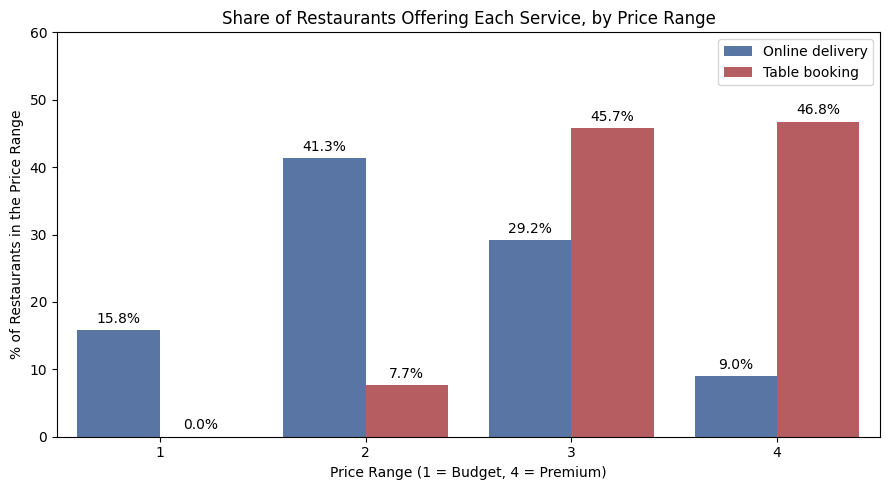

In [7]:
plot_df = by_price.reset_index().melt(
    id_vars="Price range", value_vars=["Online_Delivery_Pct", "Table_Booking_Pct"],
    var_name="Service", value_name="Percentage"
)
plot_df["Service"] = plot_df["Service"].map({"Online_Delivery_Pct": "Online delivery", "Table_Booking_Pct": "Table booking"})

plt.figure(figsize=(9, 5))
ax = sns.barplot(data=plot_df, x="Price range", y="Percentage", hue="Service", palette=["#4C72B0", "#C44E52"])
for container in ax.containers:
    ax.bar_label(container, fmt="%.1f%%", padding=3)
plt.ylim(0, 60)
plt.title("Share of Restaurants Offering Each Service, by Price Range")
plt.xlabel("Price Range (1 = Budget, 4 = Premium)")
plt.ylabel("% of Restaurants in the Price Range")
plt.legend(title="")
plt.tight_layout()
plt.show()

## 4. Are Higher-Priced Restaurants More Likely to Offer These Services?

In [8]:
df["Price Group"] = np.where(df["Price range"] >= 3, "Higher-priced (range 3-4)", "Lower-priced (range 1-2)")

group_table = df.groupby("Price Group").agg(
    Restaurants=("Restaurant ID", "size"),
    Online_Delivery_Pct=("Online Delivery", lambda s: s.mean() * 100),
    Table_Booking_Pct=("Table Booking", lambda s: s.mean() * 100),
).round(2).loc[["Lower-priced (range 1-2)", "Higher-priced (range 3-4)"]]
group_table

,Restaurants,Online_Delivery_Pct,Table_Booking_Pct
Price Group,,,
Lower-priced (range 1-2),7557,26.29,3.18
Higher-priced (range 3-4),1994,23.27,46.04


In [9]:
def association_strength(col):
    """Chi-square test of independence and Cramer's V (0 = no link, 1 = perfect link)."""
    observed = pd.crosstab(df["Price range"], df[col])
    expected = np.outer(observed.sum(axis=1), observed.sum(axis=0)) / observed.values.sum()
    chi2 = ((observed.values - expected) ** 2 / expected).sum()
    cramers_v = np.sqrt(chi2 / (observed.values.sum() * (min(observed.shape) - 1)))
    return chi2, cramers_v

strength = pd.DataFrame({
    "Service": ["Online delivery", "Table booking"],
    "Chi-square": [association_strength("Online Delivery")[0], association_strength("Table Booking")[0]],
    "Cramer's V": [association_strength("Online Delivery")[1], association_strength("Table Booking")[1]],
}).round(3)
strength

,Service,Chi-square,Cramer's V
0,Online delivery,721.379,0.275
1,Table booking,2821.581,0.544


With 3 degrees of freedom, a chi-square value above about 11.3 is already
significant at the 1% level, so both services are clearly linked to price range.
**Cramer's V** shows how strong the link is: roughly 0.1 is weak, 0.3 moderate and
0.5 or more strong.

### Robustness check: India vs outside India

In [10]:
df["Region"] = np.where(df["Currency"].str.contains("Indian"), "India", "Outside India")

region_table = (
    df.groupby(["Region", "Price range"])
    .agg(Restaurants=("Restaurant ID", "size"),
         Online_Delivery_Pct=("Online Delivery", lambda s: s.mean() * 100),
         Table_Booking_Pct=("Table Booking", lambda s: s.mean() * 100))
    .round(2)
)
region_table

Restaurants  Online_Delivery_Pct  Table_Booking_Pct
Region        Price range                                                     
India         1                   4295                16.32               0.02
              2                   2858                44.82               8.22
              3                   1111                35.82              56.17
              4                    388                11.08              64.69
Outside India 1                    149                 0.00               0.00
              2                    255                 1.96               1.57
              3                    297                 4.38               6.73
              4                    198                 5.05              11.62

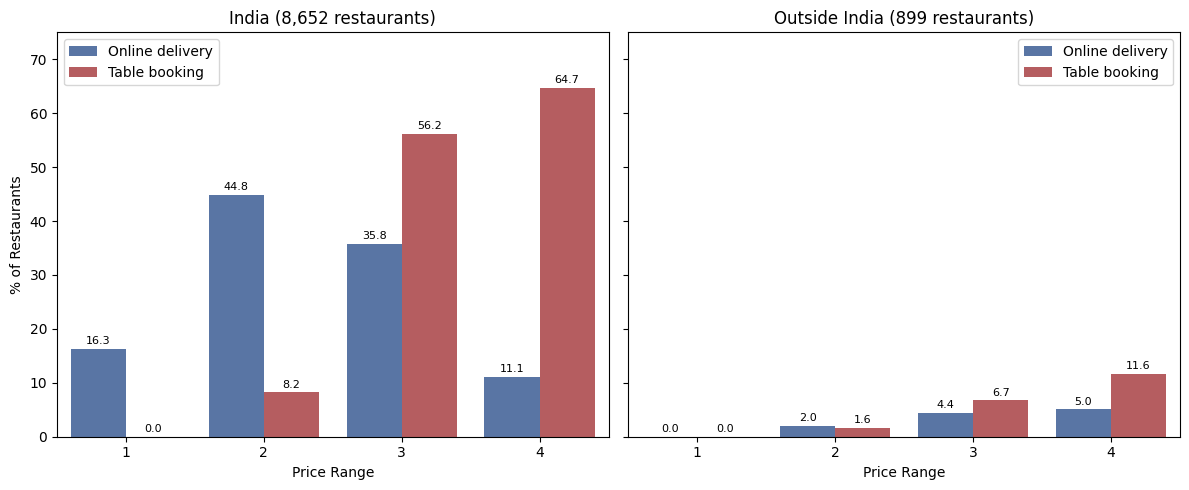

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5), sharey=True)
for ax, region in zip(axes, ["India", "Outside India"]):
    sub = region_table.loc[region].reset_index().melt(
        id_vars="Price range", value_vars=["Online_Delivery_Pct", "Table_Booking_Pct"],
        var_name="Service", value_name="Percentage")
    sub["Service"] = sub["Service"].map({"Online_Delivery_Pct": "Online delivery", "Table_Booking_Pct": "Table booking"})
    sns.barplot(data=sub, x="Price range", y="Percentage", hue="Service", palette=["#4C72B0", "#C44E52"], ax=ax)
    for container in ax.containers:
        ax.bar_label(container, fmt="%.1f", padding=2, fontsize=8)
    ax.set_title(f"{region} ({int(region_table.loc[region]['Restaurants'].sum()):,} restaurants)")
    ax.set_xlabel("Price Range")
    ax.set_ylabel("% of Restaurants")
    ax.set_ylim(0, 75)
    ax.legend(title="")
plt.tight_layout()
plt.show()

### Do restaurants combine both services?

In [12]:
combo = pd.crosstab(df["Online Delivery"], df["Table Booking"])
combo.index = ["No online delivery", "Online delivery"]
combo.columns = ["No table booking", "Table booking"]
combo

,No table booking,Table booking
No online delivery,6377,723
Online delivery,2016,435


## 5. Final Results

In [13]:
v_delivery = strength.loc[0, "Cramer's V"]
v_booking = strength.loc[1, "Cramer's V"]
hi = group_table.loc["Higher-priced (range 3-4)"]
lo = group_table.loc["Lower-priced (range 1-2)"]

task_result = pd.DataFrame({
    "Question": [
        "Online delivery: higher-priced (3-4) vs lower-priced (1-2)",
        "Table booking: higher-priced (3-4) vs lower-priced (1-2)",
        "Online delivery is most common in price range",
        "Table booking is most common in price range",
        "Strength of link with price range (Cramer's V): delivery / booking",
    ],
    "Answer": [
        f"{hi['Online_Delivery_Pct']:.2f}% vs {lo['Online_Delivery_Pct']:.2f}%",
        f"{hi['Table_Booking_Pct']:.2f}% vs {lo['Table_Booking_Pct']:.2f}%",
        f"{by_price['Online_Delivery_Pct'].idxmax()} ({by_price['Online_Delivery_Pct'].max():.2f}%)",
        f"{by_price['Table_Booking_Pct'].idxmax()} ({by_price['Table_Booking_Pct'].max():.2f}%)",
        f"{v_delivery:.2f} / {v_booking:.2f}",
    ],
})
task_result

,Question,Answer
0,Online delivery: higher-priced (3-4) vs lower-...,23.27% vs 26.29%
1,Table booking: higher-priced (3-4) vs lower-pr...,46.04% vs 3.18%
2,Online delivery is most common in price range,2 (41.31%)
3,Table booking is most common in price range,4 (46.76%)
4,Strength of link with price range (Cramer's V)...,0.28 / 0.54


## 6. Validation

In [14]:
print("Price ranges add up to total:", by_price["Restaurants"].sum() == len(df))
print("Yes + No = total (delivery):", df["Online Delivery"].sum() + (~df["Online Delivery"]).sum() == len(df))
print("Region counts add up to total:", region_table["Restaurants"].sum() == len(df))
print("Combination table adds up to total:", combo.values.sum() == len(df))

Price ranges add up to total: True
Yes + No = total (delivery): True
Region counts add up to total: True
Combination table adds up to total: True


### Business Insights

**Overall availability**

- **Only 25.66% of restaurants (2,451) offer online delivery and 12.12% (1,158)
  offer table booking.**

**Online delivery**

- **Higher-priced restaurants are not more likely to offer online delivery.**
  Only 23.27% of range 3-4 restaurants offer it, versus 26.29% of range 1-2
  restaurants.
- **Delivery peaks in the middle and falls at the top.** By price range it is
  15.77% (range 1), **41.31% (range 2)**, 29.19% (range 3) and just 9.04%
  (range 4). So the relationship is not a straight line.
- **The link is real but only moderate:** Cramer's V is 0.28 and the chi-square
  value (721) is far above the 1% significance level.

**Table booking**

- **Higher-priced restaurants are far more likely to offer table booking:** 46.04%
  of range 3-4 restaurants versus 3.18% of range 1-2 (about 14 times more).
- **It rises steeply with price:** 0.02% (range 1), 7.68% (range 2), 45.74%
  (range 3) and 46.76% (range 4). Only 1 of the 4,444 budget restaurants offers
  booking. Ranges 3 and 4 are almost identical, so booking becomes standard once
  a restaurant reaches the upper-middle price tier.
- **This is a strong link:** Cramer's V is 0.54 and the chi-square value (2,822)
  is very large.

**India vs outside India**

- **Delivery is mostly an Indian service.** Outside India, only 0% to 5.05% of
  restaurants offer it in any price range, while in India the same inverted-U
  pattern appears (16.32%, 44.82%, 35.82%, 11.08%).
- **Table booking rises with price in both regions, but more strongly in India:**
  India goes from 0.02% to 64.69% across the four ranges, and outside India from
  0% to 11.62%.

**Using both services**

- **Most restaurants offer neither:** 6,377 (66.77%) have neither service, 2,016
  (21.11%) offer only delivery, 723 (7.57%) only table booking, and just 435
  (4.55%) offer both.

**Caution**

- A link between price range and a service does not mean price causes it. A
  possible explanation is that premium restaurants focus on dine-in and
  mid-priced ones on delivery, but the data cannot test this.
- `Price range` is a relative tier (1 to 4), not an actual price, and the
  dataset is about 91% Indian, so the overall results mainly describe the Indian
  market.